In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from scipy import stats

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df['species'] = pd.Categorical.from_codes(
    iris.target,
    iris.target_names
)

print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  


In [3]:
# Dataset information
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

Dataset Shape:
(150, 5)

Column Names:
Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'species'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   sepal length (cm)  150 non-null    float64 
 1   sepal width (cm)   150 non-null    float64 
 2   petal length (cm)  150 non-null    float64 
 3   petal width (cm)   150 non-null    float64 
 4   species            150 non-null    category
dtypes: category(1), float64(4)
memory usage: 5.1 KB

Statistical Summary:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000   

In [4]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Duplicate Rows:
1


In [5]:
print(df['species'].value_counts())

print("\nAverage Measurements by Species:")

print(df.groupby('species', observed=True).mean(numeric_only=True))

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Average Measurements by Species:
            sepal length (cm)  sepal width (cm)  petal length (cm)  \
species                                                              
setosa                  5.006             3.428              1.462   
versicolor              5.936             2.770              4.260   
virginica               6.588             2.974              5.552   

            petal width (cm)  
species                       
setosa                 0.246  
versicolor             1.326  
virginica              2.026  


In [6]:
setosa = df[df['species'] == 'setosa']['petal length (cm)']
versicolor = df[df['species'] == 'versicolor']['petal length (cm)']
virginica = df[df['species'] == 'virginica']['petal length (cm)']

f_stat, p_value = stats.f_oneway(
    setosa,
    versicolor,
    virginica
)

print("F-statistic:", f_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("There is a significant difference between species.")
else:
    print("There is no significant difference.")

F-statistic: 1180.1611822529785
P-value: 2.8567766109619814e-91
There is a significant difference between species.


Data Visualization

Flower Species

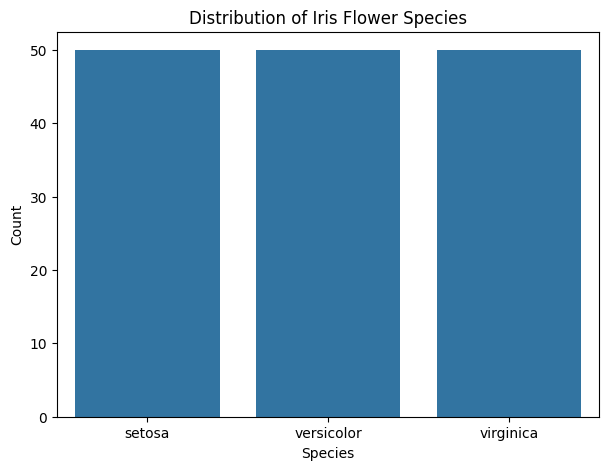

In [7]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x='species')

plt.title("Distribution of Iris Flower Species")
plt.xlabel("Species")
plt.ylabel("Count")

plt.show()

Petal Length Comparison

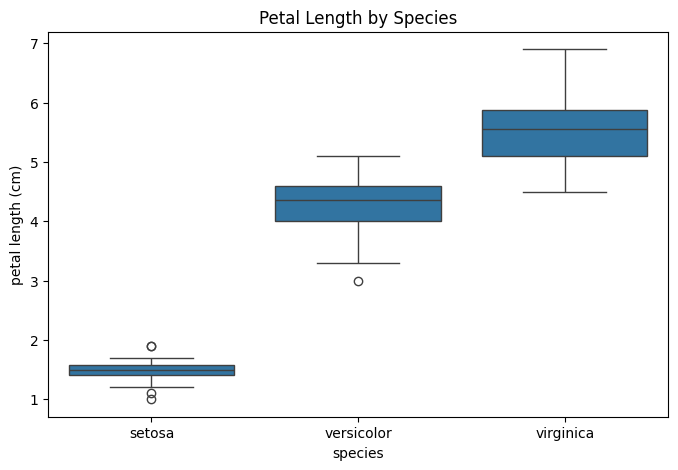

In [8]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='species',
    y='petal length (cm)'
)

plt.title("Petal Length by Species")
plt.show()

Sepal length distribution

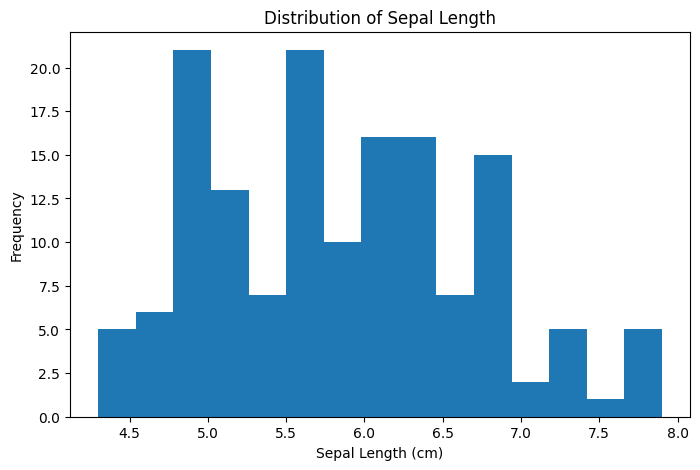

In [9]:
plt.figure(figsize=(8,5))

plt.hist(df['sepal length (cm)'], bins=15)

plt.title("Distribution of Sepal Length")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Frequency")

plt.show()

Correlation heatmap

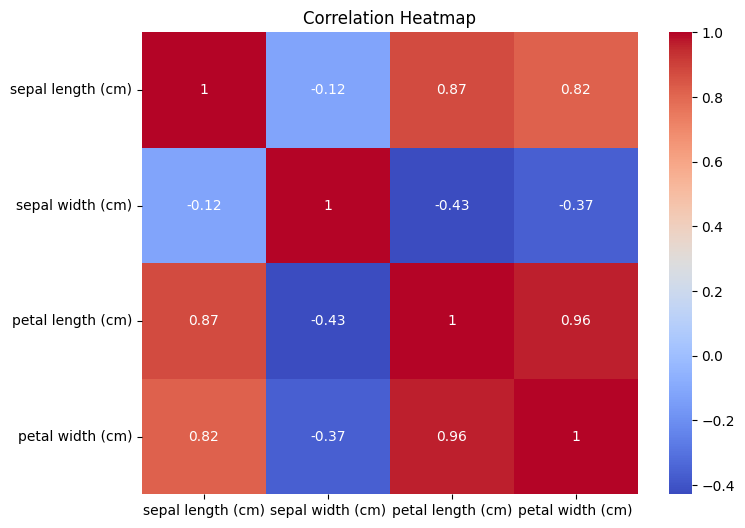

In [10]:
plt.figure(figsize=(8,6))

correlation = df.select_dtypes(
    include='number'
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")
plt.show()

Findings:
The dataset contains three different Iris flower species.



The dataset contains four numerical measurement variables.



We checked the dataset for missing values and duplicate records.



We compared the average measurements of the different species.



We used statistical testing to investigate differences in petal length.



We used graphs to understand distributions and relationships between variables.